## Identificación de patrones de abandono en estudiantes universitarios

## Comprensión del problema de intervención

#####  En el contexto global, las instituciones de educación superior enfrentan el desafío de identificar oportunamente a estudiantes con riesgo de deserción, con el propósito de disponer de información que permita el desarrollo de estrategias de acompañamiento y permanencia.

#####  En ese marco, se plantea desarrollar modelos de aprendizaje supervisado que permitan identificar estudiantes en riesgo de deserción académica y analizar qué características presentan mayor relevancia predictiva contemplando, además, posibles diferencias entre grupos disciplinares de carreras.

## Comprensión de datos

### El set de datos

##### El set de datos que se utiliza pertenece a una institución portuguesa de educación superior que contiene 4424 observaciones y 36 variables relacionadas con antecedentes académicos, características demográficas y factores socioeconómicos, y plantea originalmente la situación académica del estudiante como un problema de clasificación en tres categorías: abandono, matriculado y graduado.

##### Fuente: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

### Recuperación del dataset

In [1]:
# Importar librerias
import os 

import pandas as pd
import numpy as np
import math

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import preprocessing
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import KFold

In [2]:
# Leer archivo del dataset
ruta = os.path.join("..", "data", "Higher_Education_Portugal.csv") #construye ruta de archivos compatible con diferentes sistemas operativos.
df = pd.read_csv(ruta, sep=";") 

In [3]:
# Configuración general
df.columns = df.columns.str.strip() #Elimina espacios en los nombres de las columnas
pd.set_option('display.max_columns',None) # permite visualizar todas las columnas. 

### Análisis de datos

In [4]:
df.sample(20) #Visualizar 20 registros del dataframe al azar

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
1546,1,18,1,9773,1,1,125.0,1,19,37,9,5,122.2,0,0,0,0,0,0,18,0,0,6,7,5,12.600000,0,0,6,6,5,11.800000,0,11.1,0.6,2.02,Enrolled
1517,1,17,1,171,1,1,135.0,1,19,1,4,1,131.9,1,0,0,1,1,0,19,0,6,12,12,12,13.583333,0,4,11,12,11,13.583333,0,8.9,1.4,3.51,Graduate
2572,1,1,1,9238,1,1,133.1,1,1,1,4,10,110.0,0,0,1,1,0,0,23,0,0,6,8,6,12.625000,0,0,6,6,6,14.166667,0,12.7,3.7,-1.70,Graduate
1204,1,39,1,9238,1,1,140.0,1,34,34,0,0,114.0,1,0,0,0,0,0,28,0,0,6,11,1,13.000000,0,0,6,12,0,0.000000,0,9.4,-0.8,-3.12,Dropout
3569,1,39,1,9085,1,19,133.1,1,3,1,2,5,103.0,0,0,0,1,1,0,25,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
273,1,1,1,9500,1,1,143.0,1,5,1,2,5,136.7,0,0,0,1,0,0,19,0,2,7,8,7,12.670000,0,1,8,8,8,13.550000,0,11.1,0.6,2.02,Graduate
3146,1,1,1,9238,1,1,126.0,1,3,1,5,5,125.7,0,0,0,1,0,1,18,0,0,6,6,6,11.333333,0,0,6,8,6,11.333333,0,15.5,2.8,-4.06,Graduate
1479,1,1,1,9085,1,1,123.0,1,1,1,4,9,116.7,1,0,0,1,1,1,20,0,0,6,10,4,13.200000,0,0,6,8,0,0.000000,0,12.4,0.5,1.79,Dropout
786,1,1,1,9070,1,1,153.0,1,3,3,1,2,146.7,1,0,0,1,0,0,18,0,0,6,6,6,13.666667,0,0,6,6,5,14.000000,0,12.7,3.7,-1.70,Graduate
3206,1,1,1,9147,1,1,146.0,1,5,1,1,5,144.6,0,0,0,1,1,0,18,0,0,5,5,5,13.000000,0,0,5,6,5,13.333333,0,16.2,0.3,-0.92,Graduate


In [5]:
print ('Información general del dataframe')
df.info()

Información general del dataframe
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father'

##### A partir del análisis de `df.info()` se observan las columnas del dataframe, la cantidad de valores no nulos por columna y finalmente, el tipo de datos. 

##### En relación con los datos, se puede ver que los datos se encuentran completos, lo cual facilita el análisis al no requerir tratamientos adicionales de imputación o eliminación de registros. No obstante, es importante considerar que la ausencia de valores nulos no garantiza la calidad total de los datos, por lo que se continuará evaluando su consistencia en las siguientes etapas.¶

##### En cuanto al tipo de datos, la mayoría de las variables del dataset son de tipo numérico (`int64` y `float64`). Si bien muchas variables aparecen como numéricas, varias de ellas representan categorías codificadas (por ejemplo: estado civil, género, tipo de curso), por lo que deberán ser tratadas como variables categóricas en el análisis. Por otro lado, las variables de tipo `float64` corresponden principalmente a métricas continuas, como calificaciones y variables macroeconómicas (tasa de desempleo, inflación y PIB), las cuales pueden ser analizadas directamente como variables numéricas.

In [6]:
print(df.columns.tolist())  #Muestra las columnas del dataframe. 

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [7]:
#Obtener estadísticas descriptivas de las variables numéricas del dataset
cols_categoricas = [
    'Marital status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]
# display(df[cols_categoricas])

cols_numericas = [
    'Age at enrollment',
    'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate', 'Inflation rate', 'GDP'
]

cols_numericas_bivariado = [
    'Age at enrollment', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)', 'Unemployment rate',
    'Inflation rate', 'GDP'
]


cols_categoricas_bivariado = [
    'Marital status', 'Application mode', 'Application order', 'Daytime/evening attendance', 
    'Previous qualification','Tuition fees up to date', 'Displaced', 'Educational special needs', 
    'Debtor','Gender', 'Scholarship holder', 'International'
]

print('Estadísticas descriptivas')
df[cols_numericas].describe()

Estadísticas descriptivas


,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [8]:
#Definir grupos de características para el análisis descriptivo y bivariado
cols_categoricas = [
    'Marital status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]
# display(df[cols_categoricas])

cols_numericas = [
    'Age at enrollment',
    'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate', 'Inflation rate', 'GDP'
]

cols_numericas_bivariado = [
    'Age at enrollment', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)', 'Unemployment rate',
    'Inflation rate', 'GDP'
]

cols_categoricas_bivariado = [
    'Marital status', 'Application mode', 'Application order', 'Daytime/evening attendance', 
    'Previous qualification', "Mother's occupation", "Father's occupation", 'Tuition fees up to date', 
    'Displaced', 'Educational special needs', 'Debtor','Gender', 'Scholarship holder', 'International'
]

In [9]:
# Obtener estadísticas descriptivas de las variables numéricas del dataset

print('Estadísticas descriptivas')
df[cols_numericas].describe()

Estadísticas descriptivas


,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [10]:
#Informar la cantidad de valores únicos por variable
for col in df.columns:
    print(col, df[col].nunique())

Marital status 6
Application mode 18
Application order 8
Course 17
Daytime/evening attendance 2
Previous qualification 17
Previous qualification (grade) 101
Nacionality 21
Mother's qualification 29
Father's qualification 34
Mother's occupation 32
Father's occupation 46
Admission grade 620
Displaced 2
Educational special needs 2
Debtor 2
Tuition fees up to date 2
Gender 2
Scholarship holder 2
Age at enrollment 46
International 2
Curricular units 1st sem (credited) 21
Curricular units 1st sem (enrolled) 23
Curricular units 1st sem (evaluations) 35
Curricular units 1st sem (approved) 23
Curricular units 1st sem (grade) 805
Curricular units 1st sem (without evaluations) 11
Curricular units 2nd sem (credited) 19
Curricular units 2nd sem (enrolled) 22
Curricular units 2nd sem (evaluations) 30
Curricular units 2nd sem (approved) 20
Curricular units 2nd sem (grade) 786
Curricular units 2nd sem (without evaluations) 10
Unemployment rate 10
Inflation rate 9
GDP 10
Target 3


No se detectan variables con un único valor, por lo que no es necesario eliminar variables por ausencia de variabilidad.

In [11]:
# Mostrar la frecuencia de cada categoría en las variables categóricas

for col in cols_categoricas:
     print(df[col].value_counts())

Marital status
1    3919
2     379
4      91
5      25
6       6
3       4
Name: count, dtype: int64
Application mode
1     1708
17     872
39     785
43     312
44     213
7      139
18     124
42      77
51      59
16      38
53      35
15      30
5       16
10      10
2        3
57       1
26       1
27       1
Name: count, dtype: int64
Application order
1    3026
2     547
3     309
4     249
5     154
6     137
9       1
0       1
Name: count, dtype: int64
Course
9500    766
9147    380
9238    355
9085    337
9773    331
9670    268
9991    268
9254    252
9070    226
171     215
8014    215
9003    210
9853    192
9119    170
9130    141
9556     86
33       12
Name: count, dtype: int64
Daytime/evening attendance
1    3941
0     483
Name: count, dtype: int64
Previous qualification
1     3717
39     219
19     162
3      126
12      45
40      40
42      36
2       23
6       16
9       11
4        8
38       7
43       6
10       4
15       2
5        1
14       1
Name: count, d

In [12]:
# Determinar la cantidad de valores nulos 
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [13]:
# Determinar la cantidad de filas duplicadas. 
df.duplicated().sum()

np.int64(0)

### Análisis exploratorio de datos

#### Análisis univariado

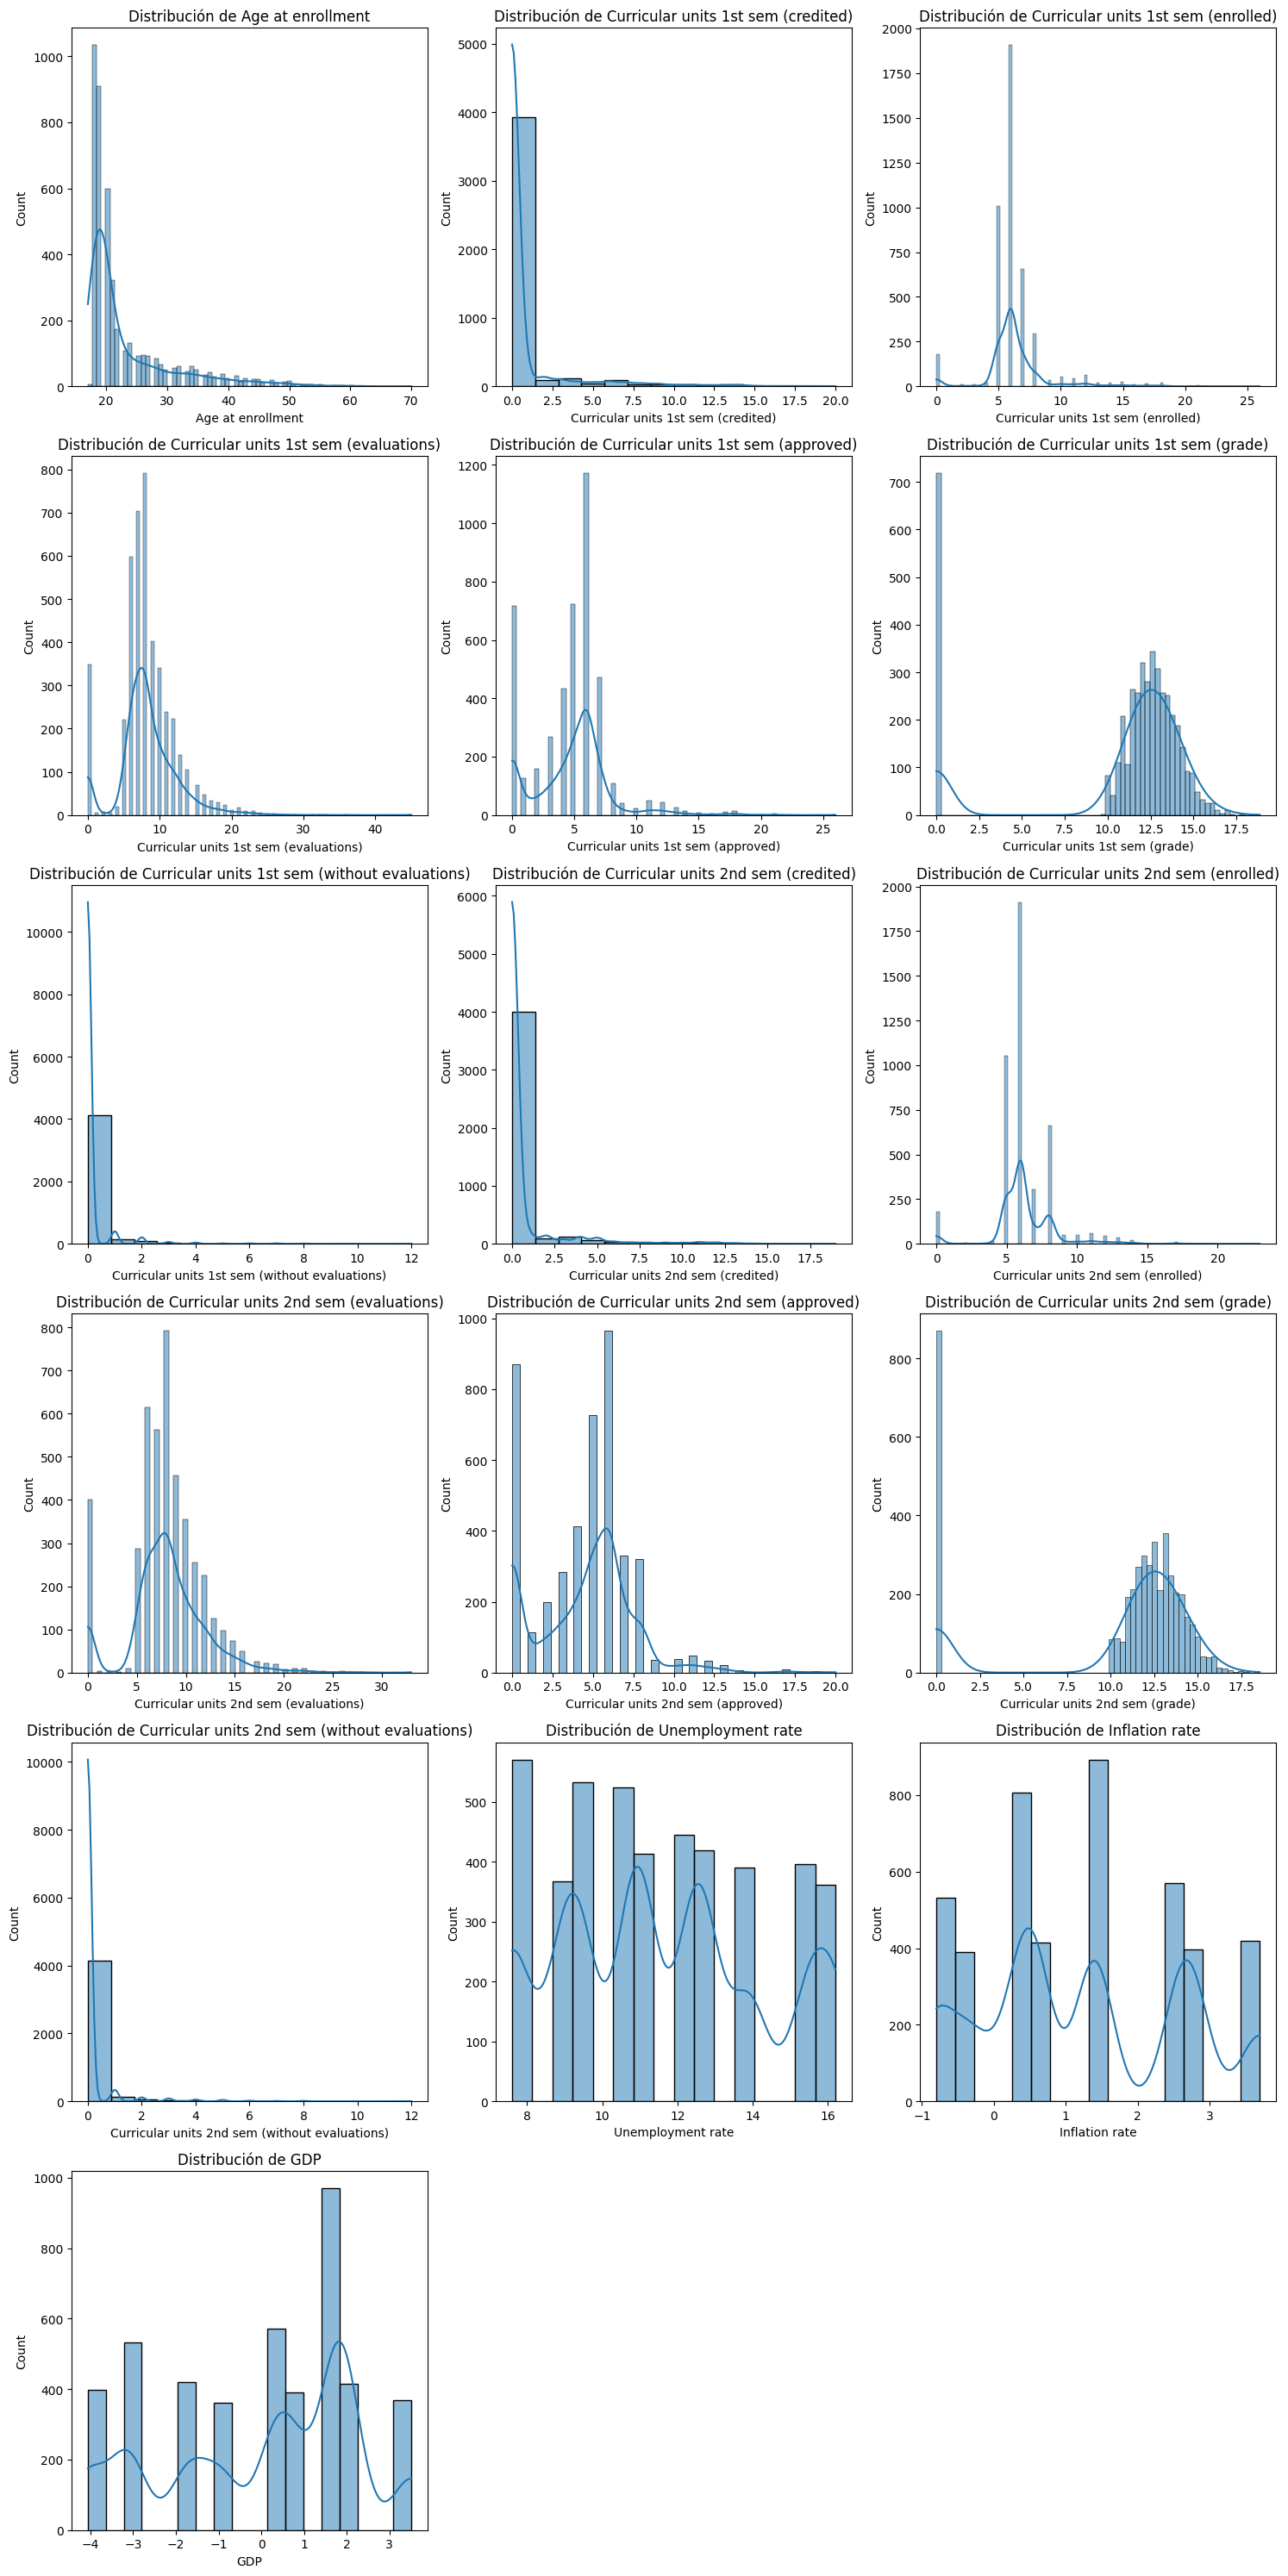

In [14]:
# Histograma para cada variable numérica
plt.figure(figsize=(15,30))
for i,col in enumerate (cols_numericas,1):
    plt.subplot(6,3,i)
    sns.histplot(df[col],kde=True)
    plt.title (f'Distribución de {col}')
plt.tight_layout()
plt.show()

El análisis univariado de las variables numéricas permite visualizar distribuciones heterogéneas, con distinta dispersión y presencia de asimetrías en algunas variables. Estas características serán consideradas de manera más exhaustiva en la etapa de preparación de datos

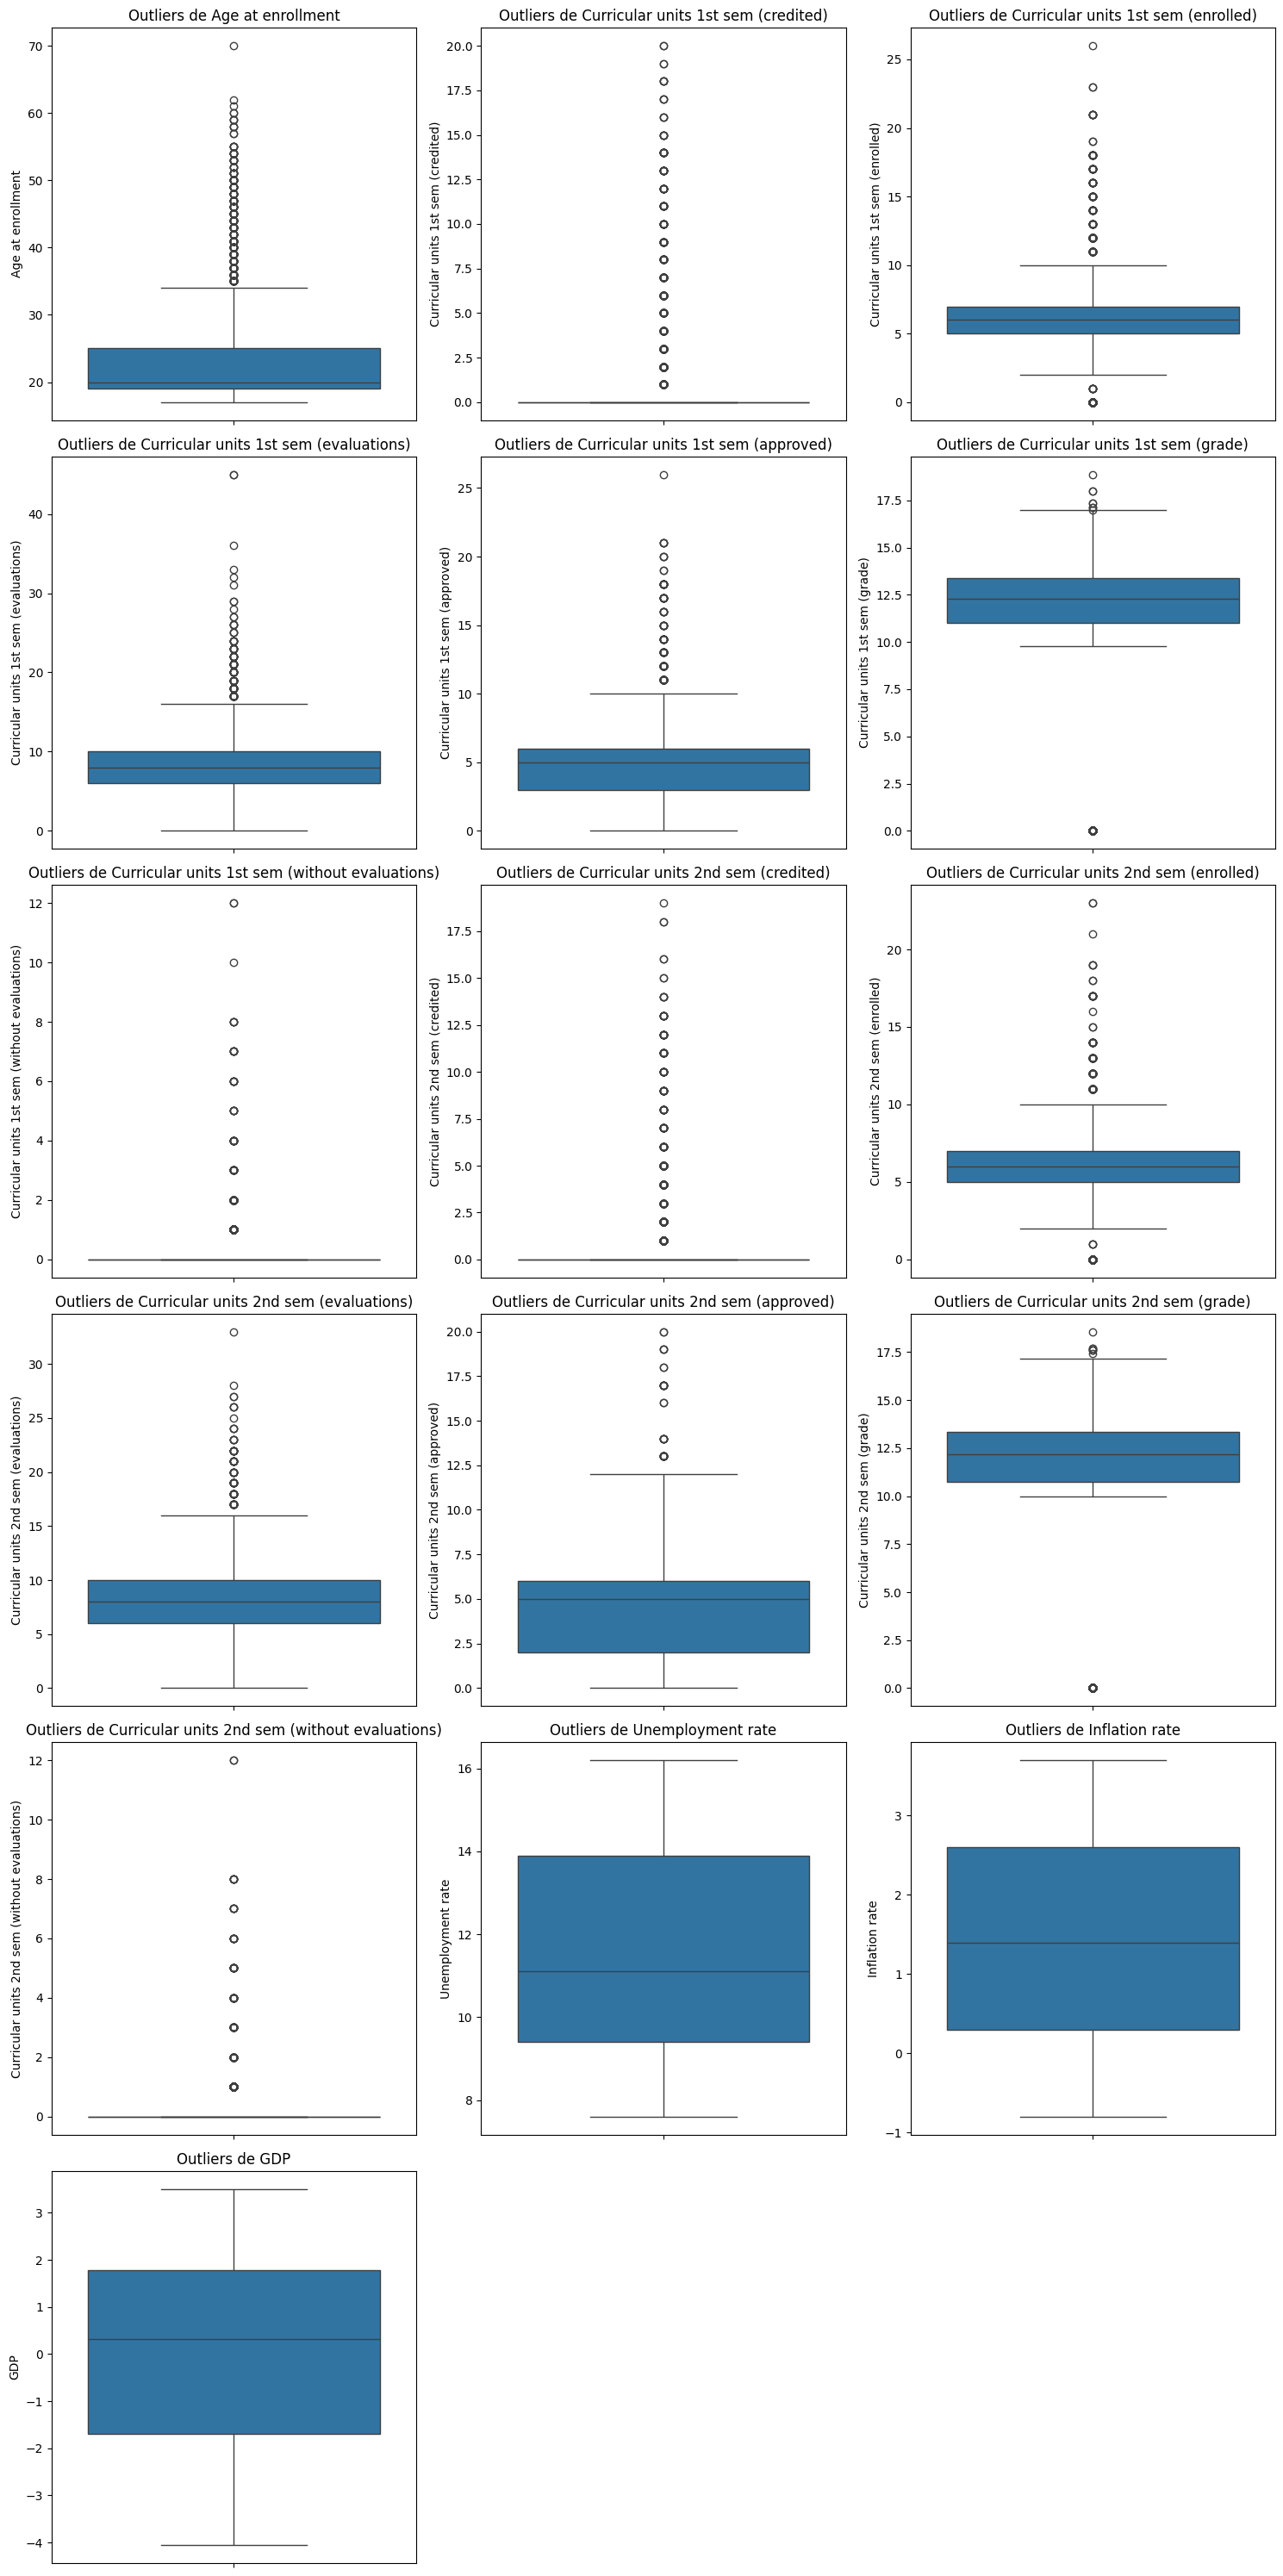

In [15]:
# Boxplot para detección de valores atípicos (outliers)

plt.figure(figsize=(15,30))
for i,col in enumerate (cols_numericas,1):
    plt.subplot(6,3,i)
    sns.boxplot(y= df[col])
    plt.title (f'Outliers de {col}')
plt.tight_layout()
plt.show()

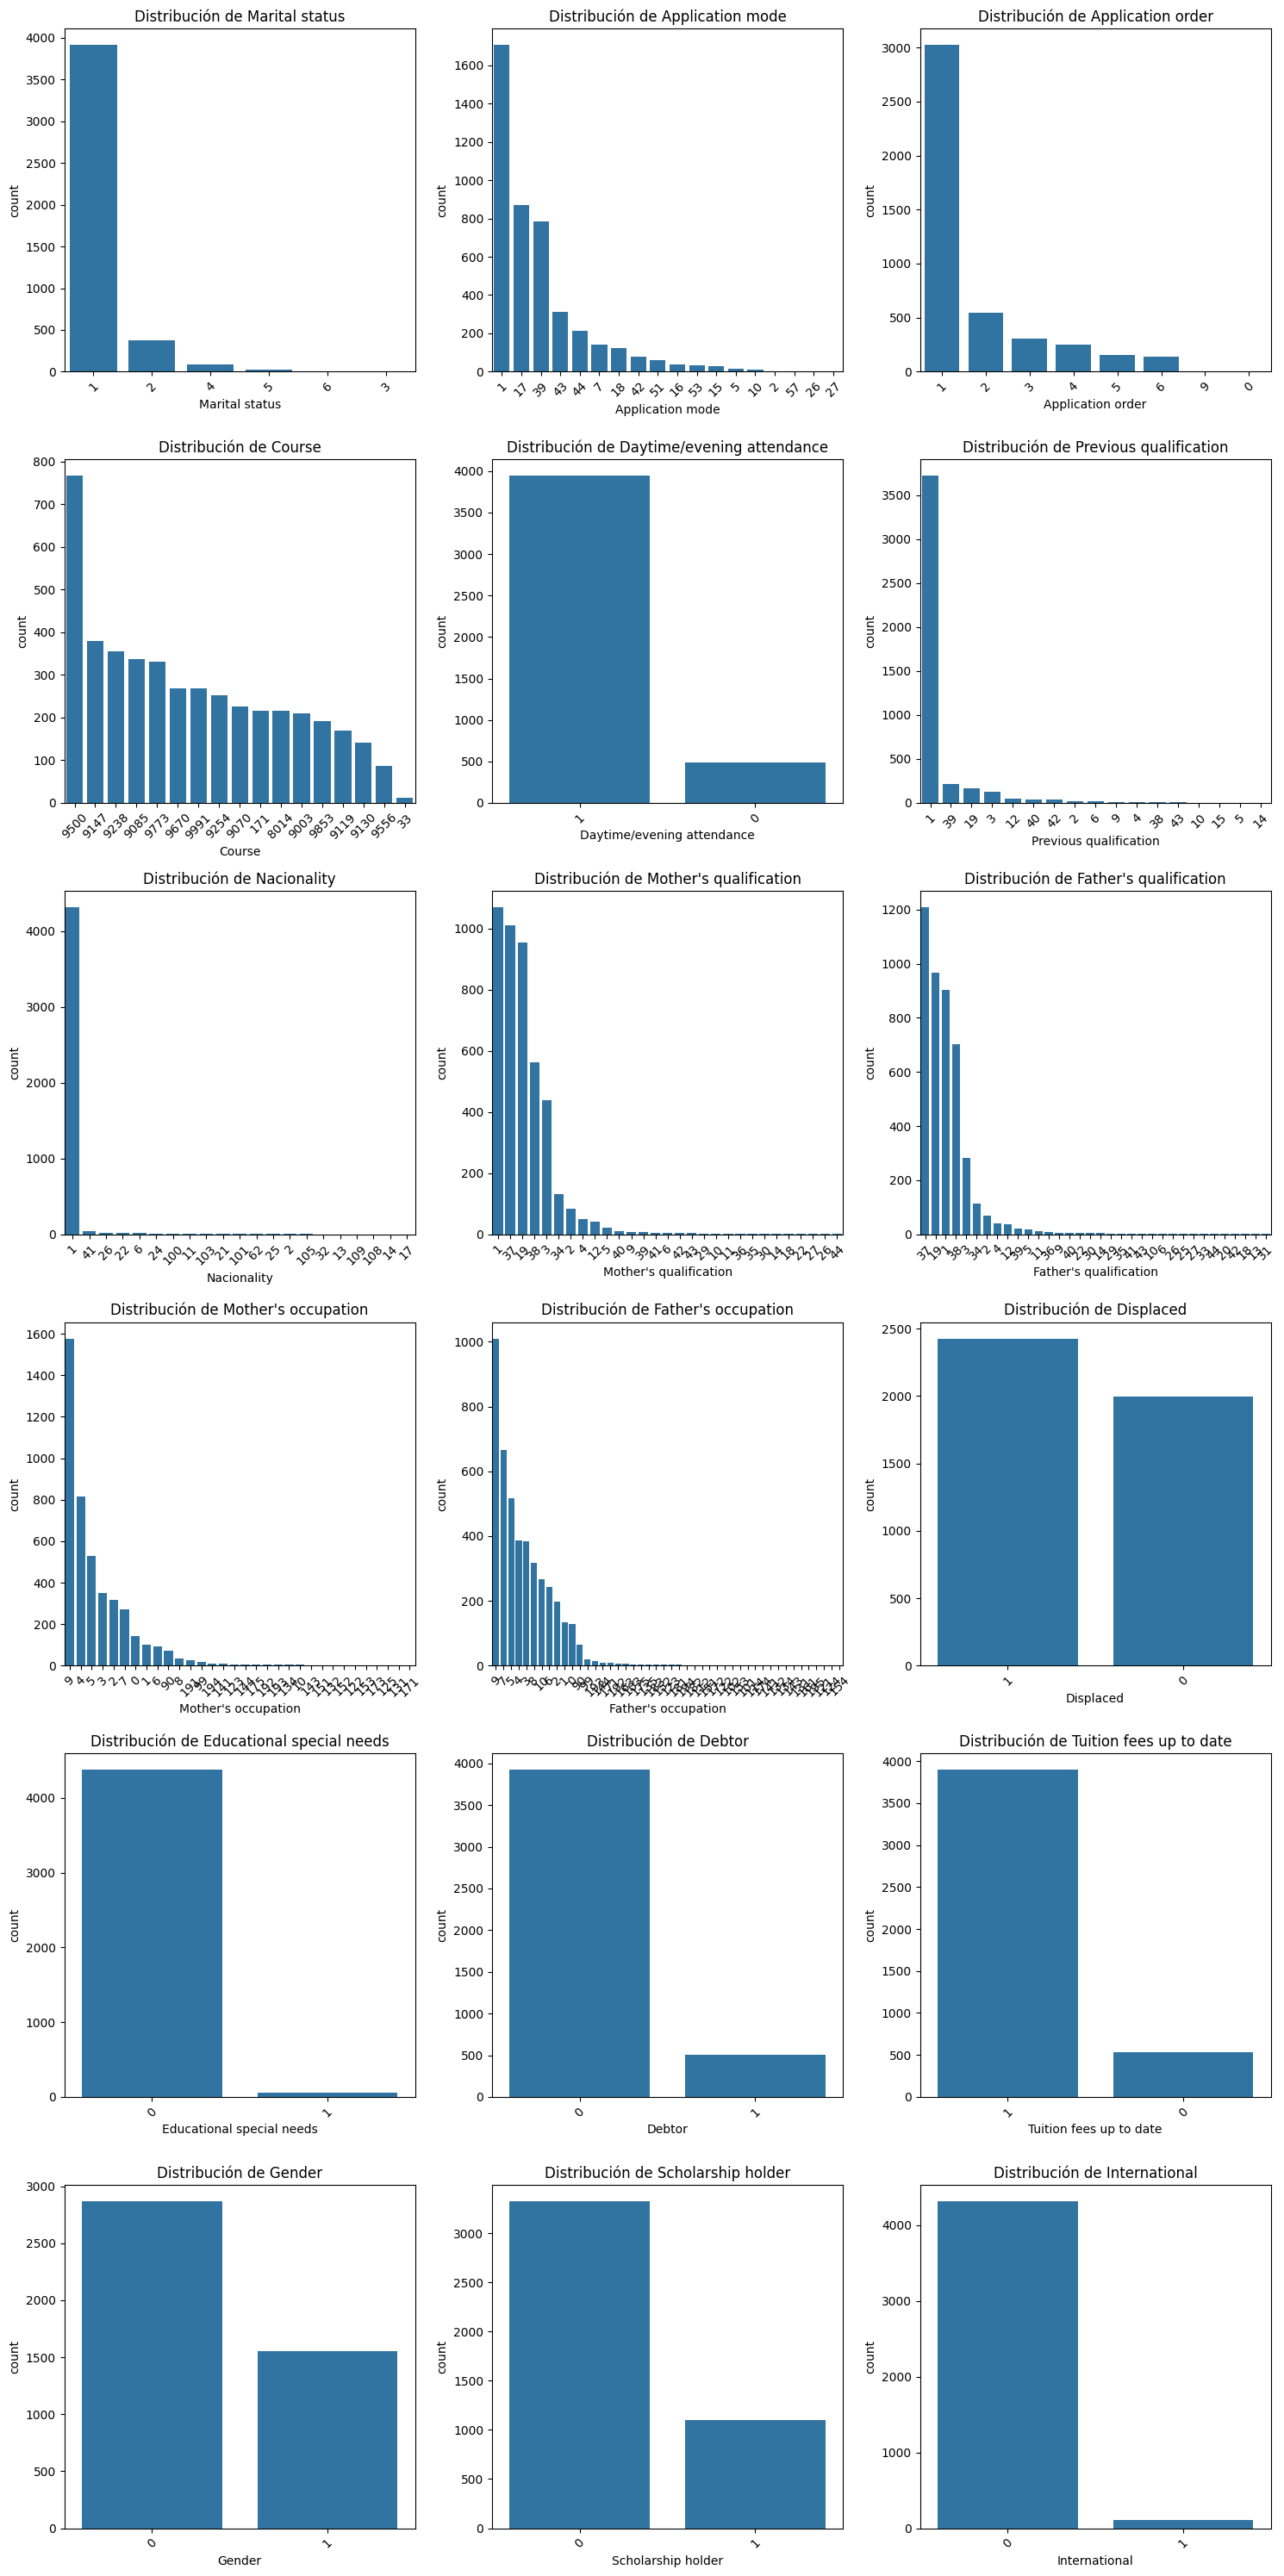

In [16]:
# Countplot para medir frecuencia de variables categóricas

plt.figure(figsize=(15,30))
for i,col in enumerate (cols_categoricas,1):
    plt.subplot(6,3,i)
    order =df[col].value_counts().index
    sns.countplot(data=df,x= col,order=order)
    plt.title (f'Distribución de {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
plt.show()

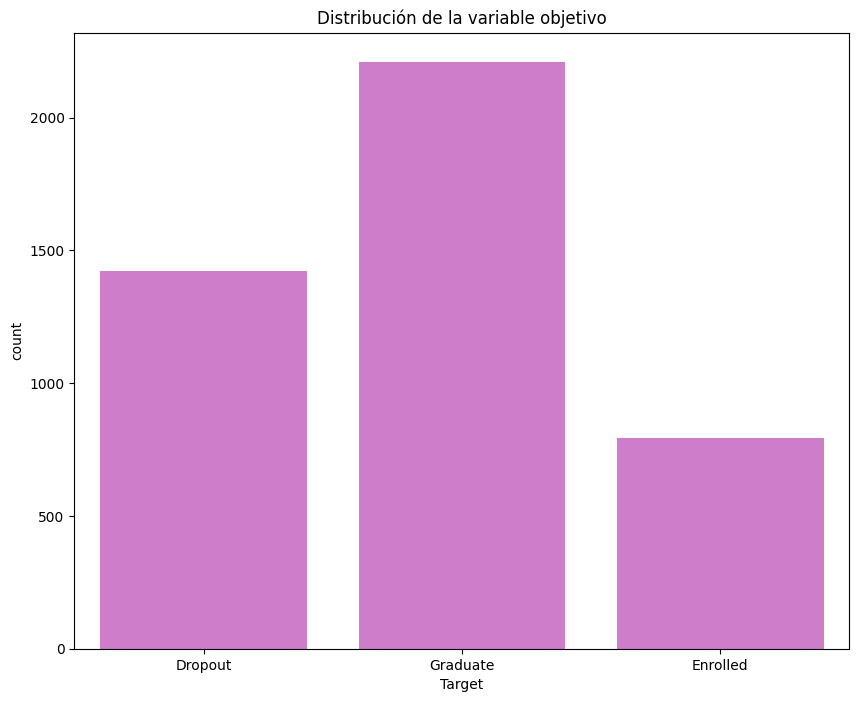

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64


In [17]:
# Distribución de la variable objetivo/Target
plt.figure(figsize=(10,8))
sns.countplot(data=df, x='Target',color='orchid')
plt.title('Distribución de la variable objetivo')
plt.show()

print(df['Target'].value_counts())
print(df['Target'].value_counts(normalize=True) * 100)

La variable objetivo presenta una distribución desigual entre sus categorías. La clase Graduate concentra aproximadamente el 49,9% de los casos, seguida por Dropout con 32,1%, mientras que Enrolled representa el 17,9%. Esto evidencia un desbalance moderado de clases, que será considerado en la etapa de preparación de datos. 

#### Análisis bivariado

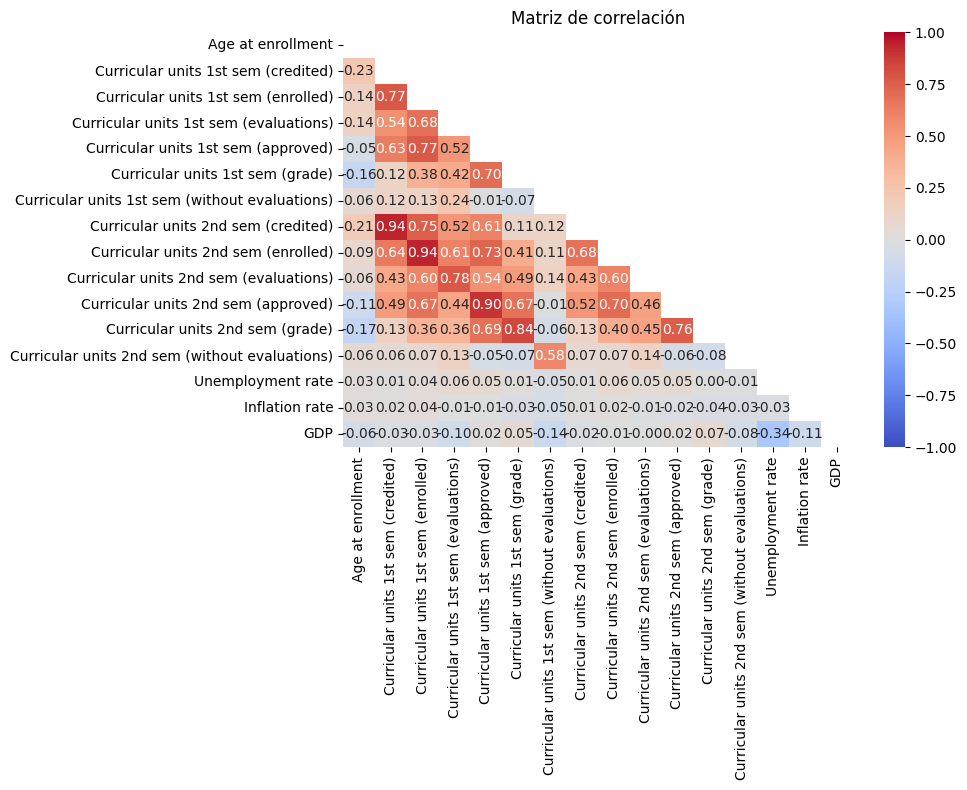

In [18]:
# Mapa de correlación
plt.figure(figsize=(10,8))
corr = df[cols_numericas].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask = mask, annot=True, fmt ='.2f', cmap = "coolwarm" ,vmin= -1, vmax= 1)
plt.title ('Matriz de correlación')
plt.tight_layout()
plt.show()

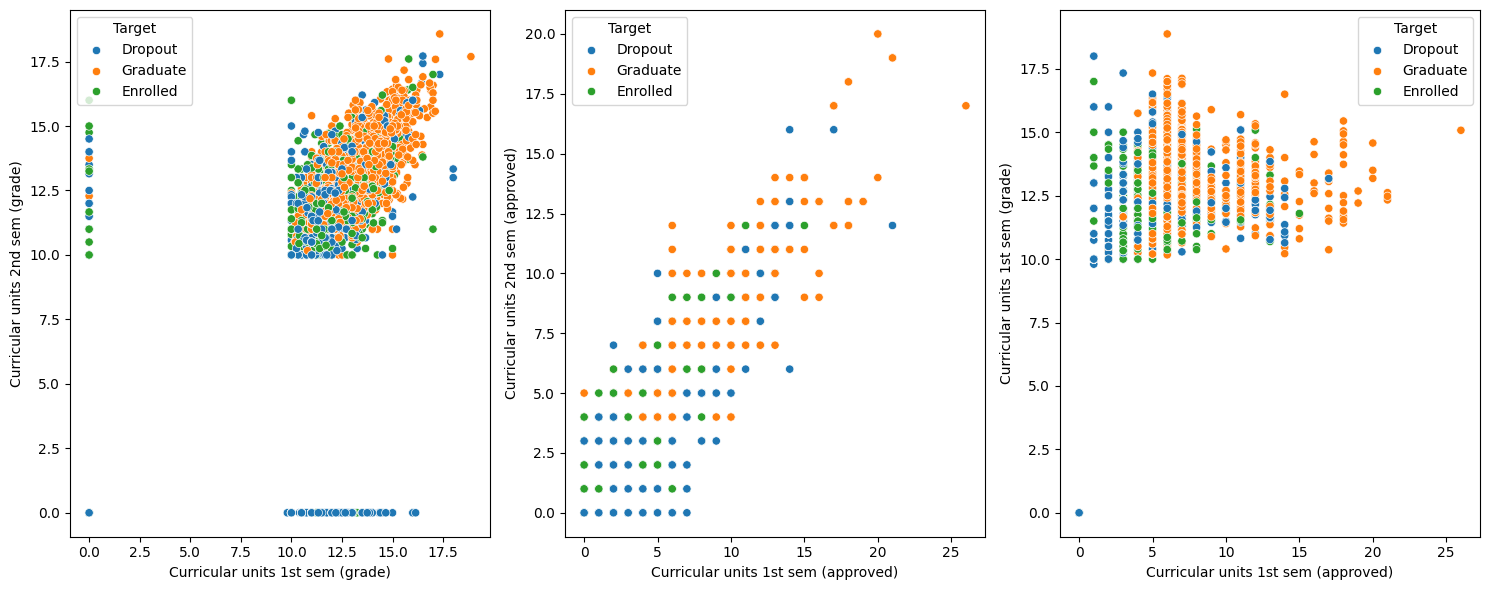

In [19]:
# Analizar la relación entre variables numéricas altamente correlacionadas
# y observar su comportamiento según la variable objetivo

plt.figure (figsize = (15,6))
plt.subplot(1,3,1)
sns.scatterplot (df, x= 'Curricular units 1st sem (grade)', y='Curricular units 2nd sem (grade)',hue = 'Target')

plt.subplot(1,3,2)
sns.scatterplot (df, x= 'Curricular units 1st sem (approved)', y='Curricular units 2nd sem (approved)',hue = 'Target')

plt.subplot(1,3,3)
sns.scatterplot (df, x= 'Curricular units 1st sem (approved)', y='Curricular units 1st sem (grade)',hue = 'Target')


plt.tight_layout()
plt.show()

##### Variables categóricas vs target

In [20]:
# Para facilitar la interpretación en los diagramas se asocian los códigos numéricos con etiquetas descriptivas de algunas variables categóricas

etiquetas_categoricas = {
    'Marital status': {
        1: 'Soltero/a',
        2: 'Casado/a',
        3: 'Viudo/a',
        4: 'Divorciado/a',
        5: 'Unión de hecho',
        6: 'Separado/a'
    },

    'Gender': {
        0: 'Mujer',
        1: 'Varón'
    },

    'Debtor': {
        0: 'No',
        1: 'Sí'
    },

    'Tuition fees up to date': {
        0: 'No',
        1: 'Sí'
    },

    'Scholarship holder': {
        0: 'No',
        1: 'Sí'
    },

    'International': {
        0: 'No',
        1: 'Sí'
    },

    'Educational special needs': {
        0: 'No',
        1: 'Sí'
    },

    'Displaced': {
        0: 'No',
        1: 'Sí'
    },

    'Daytime/evening attendance': {
        0: 'Nocturno',
        1: 'Diurno'
    }
}

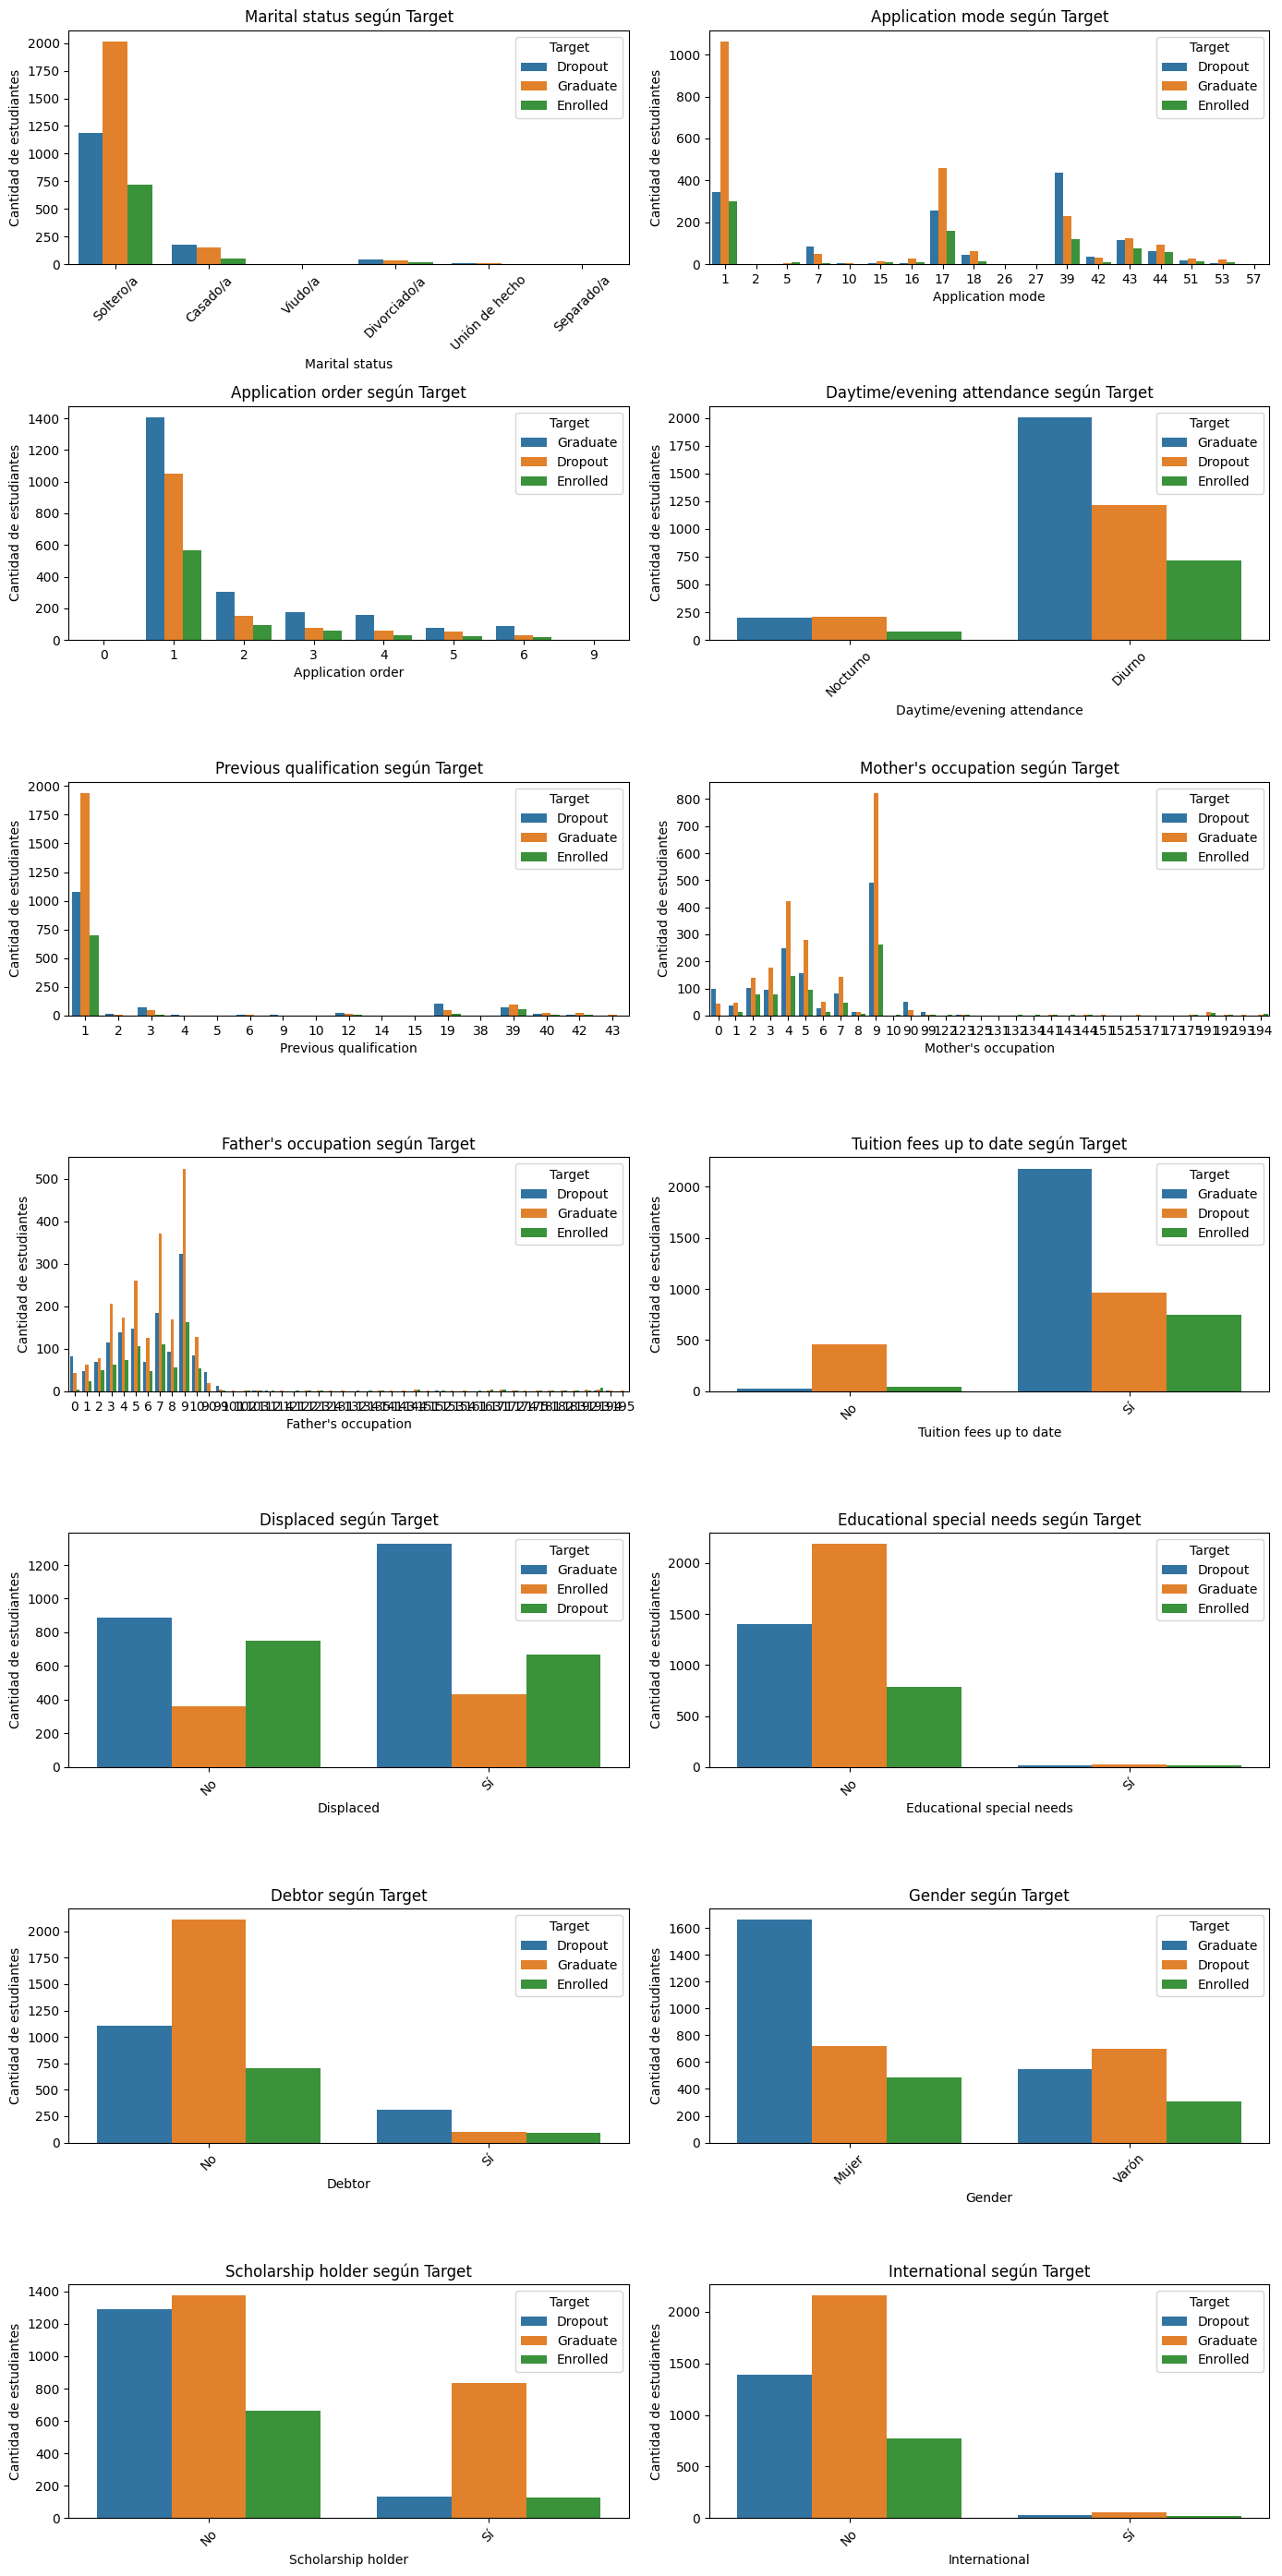

In [21]:
# Generar gráficos countplot para analizar la relación entre las variables categóricas seleccionadas y la variable objetivo/ Target

cols = 2
rows = math.ceil(len(cols_categoricas_bivariado) / cols)

plt.figure(figsize=(14, 4 * rows))

for i, col in enumerate(cols_categoricas_bivariado, 1):
    plt.subplot(rows, cols, i)

    sns.countplot(data=df, x=col, hue='Target')

    plt.title(f'{col} según Target')
    plt.xlabel(col)
    plt.ylabel('Cantidad de estudiantes')

    if col in etiquetas_categoricas:
        valores = sorted(df[col].dropna().unique())
        etiquetas = [etiquetas_categoricas[col][v] for v in valores]

        plt.xticks(
            range(len(valores)),
            etiquetas,
            rotation=45
        )

plt.tight_layout()
plt.show()

In [22]:
#  # Calcular para cada variable categórica seleccionada qué porcentaje corresponde a cada categoría de target

for col in cols_categoricas_bivariado:
    print(f"\n{col}")

    tabla = pd.crosstab(
        df[col],
        df['Target'],
        normalize='index'
    ) * 100

    print(tabla.round(2))


Marital status
Target          Dropout  Enrolled  Graduate
Marital status                             
1                 30.21     18.37     51.42
2                 47.23     13.72     39.05
3                 25.00     50.00     25.00
4                 46.15     17.58     36.26
5                 44.00     12.00     44.00
6                 66.67     16.67     16.67

Application mode
Target            Dropout  Enrolled  Graduate
Application mode                             
1                   20.20     17.56     62.24
2                   66.67      0.00     33.33
5                   12.50     50.00     37.50
7                   61.15      5.04     33.81
10                  30.00      0.00     70.00
15                  16.67     33.33     50.00
16                  13.16     21.05     65.79
17                  29.36     18.23     52.41
18                  36.29     12.90     50.81
26                 100.00      0.00      0.00
27                 100.00      0.00      0.00
39              

##### A partir del análisis de las variables categóricas se observan diferencias en la distribución de Target entre algunas categorías.

##### En el caso de la modalidad de cursada, la mayoría de los estudiantes asiste en horario diurno. En el turno nocturno, las proporciones de abandono y graduación son similares, mientras que en el turno diurno la proporción de graduados es mayor. Como el grupo nocturno tiene menos estudiantes, esta comparación debe interpretarse con cautela.

##### De igual modo, se observan diferencias claras en variables como Scholarship holder, donde la distribución de Target cambia según el estudiante sea o no becario.

##### Variables numéricas vs target

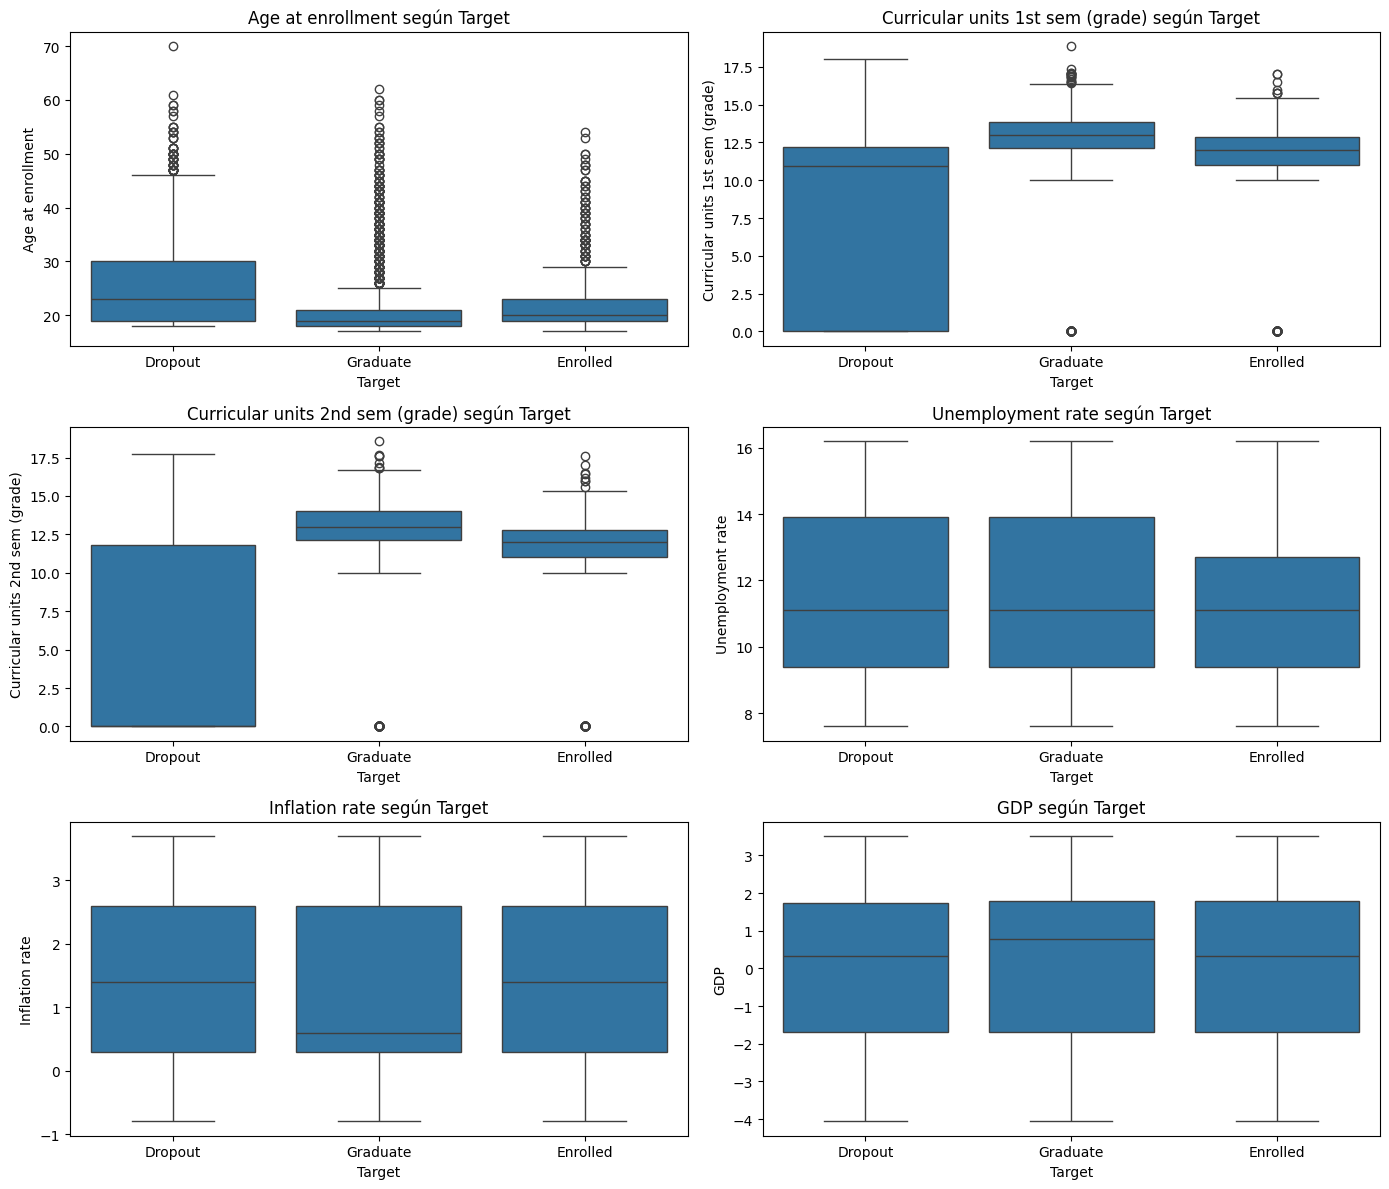

In [23]:
# Generar gráficos boxplot para analizar la relación entre las variables numéricas seleccionadas y la variable objetivo/ Target

cols = 2
rows = math.ceil(len(cols_numericas_bivariado) / cols)

plt.figure(figsize=(14, 4 * rows))

for i, col in enumerate(cols_numericas_bivariado, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x='Target', y=col, data=df)
    plt.title(f'{col} según Target')

plt.tight_layout()
plt.show()

In [24]:
# Asociar los códigos de la variable Course con los nombres de las carreras para facilitar la interpretación en tablas y gráficos 

nombres_carreras = {
    33: 'Biofuel Production Technologies',
    171: 'Animation and Multimedia Design',
    8014: 'Social Service (evening attendance)',
    9003: 'Agronomy',
    9070: 'Communication Design',
    9085: 'Veterinary Nursing',
    9119: 'Informatics Engineering',
    9130: 'Equinculture',
    9147: 'Management',
    9238: 'Social Service',
    9254: 'Tourism',
    9500: 'Nursing',
    9556: 'Oral Hygiene',
    9670: 'Advertising and Marketing Management',
    9773: 'Journalism and Communication',
    9853: 'Basic Education',
    9991: 'Management (evening attendance)'
}

In [25]:
# Crear una tabla de porcentajes ordenada de manera descendente por dropout según la carrera. 
tabla_course_pct = pd.crosstab(
    df['Course'],
    df['Target'],
    normalize='index'
) * 100

tabla_course_pct = tabla_course_pct.rename(index=nombres_carreras)

tabla_course_pct = tabla_course_pct.sort_values(
    by='Dropout',
    ascending=False
)

print(tabla_course_pct.round(2))

Target                                Dropout  Enrolled  Graduate
Course                                                           
Biofuel Production Technologies         66.67     25.00      8.33
Equinculture                            55.32     14.89     29.79
Informatics Engineering                 54.12     37.65      8.24
Management (evening attendance)         50.75     20.15     29.10
Basic Education                         44.27     26.04     29.69
Agronomy                                40.95     17.62     41.43
Oral Hygiene                            38.37     19.77     41.86
Animation and Multimedia Design         38.14     17.21     44.65
Tourism                                 38.10     16.27     45.63
Advertising and Marketing Management    35.45     17.91     46.64
Management                              35.26     28.42     36.32
Social Service (evening attendance)     33.02      9.77     57.21
Journalism and Communication            30.51     10.27     59.21
Veterinary

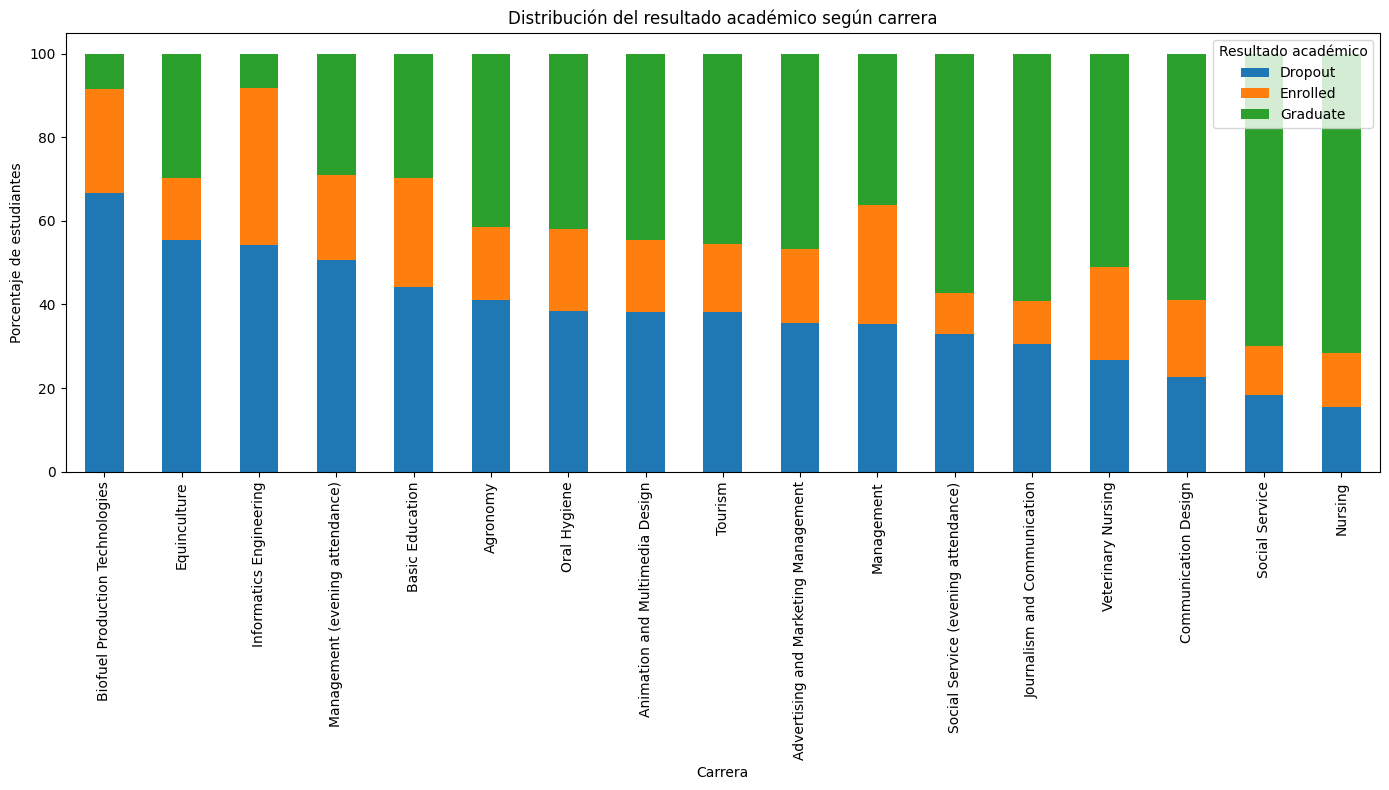

In [26]:
# Generar un gráfico de barras apiladas para analizar la distribución porcentual de Target según la carrera

tabla_course_pct = tabla_course_pct.rename(index=nombres_carreras)

tabla_course_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(14,8)
)

plt.title('Distribución del resultado académico según carrera')
plt.xlabel('Carrera')
plt.ylabel('Porcentaje de estudiantes')
plt.legend(title='Resultado académico')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## Preparación de los datos

##### Se realizan transformaciones sobre algunas variables con el objetivo de facilitar su interpretación y preparación para el modelado predictivo.

In [27]:
# Crear el dataframe df_binario que se compone de los registros donde Target= 'Graduate' O 'Dropout'
df_binario = df[df['Target'] != 'Enrolled'].copy()
print(df_binario['Target'].value_counts())
print(df_binario['Target'].value_counts(normalize=True) * 100)

Target
Graduate    2209
Dropout     1421
Name: count, dtype: int64
Target
Graduate    60.853994
Dropout     39.146006
Name: proportion, dtype: float64


Luego de excluir la categoría Enrolled, el conjunto queda conformado por 2.209 casos Graduate y 1.421 casos Dropout.

In [28]:
# Asignar 1 a Dropout y 0 a Graduate para que la variable objetivo esté en formato binario.

df_binario['Target'] = df_binario['Target'].map({
    'Graduate': 0,
    'Dropout': 1
})

In [29]:
# Agrupar las carreras según campos disciplinares ISCED 

campo_isced = {
    33: 'Ingeniería, industria y construcción',
    171: 'Artes y humanidades',
    8014: 'Salud y Bienestar',
    9003: 'Agricultura, silvicultura, pesca y veterinaria',
    9070: 'Artes y humanidades',
    9085: 'Agricultura, silvicultura, pesca y veterinaria',
    9119: 'Tecnologías de la Información y la Comunicación',
    9130: 'Agricultura, silvicultura, pesca y veterinaria',
    9147: 'Administración de empresas y derecho',
    9238: 'Salud y Bienestar',
    9254: 'Servicios',
    9500: 'Salud y Bienestar',
    9556: 'Salud y Bienestar',
    9670: 'Administración de empresas y derecho',
    9773: 'Ciencias Sociales, periodismo y comunicación',
    9853: 'Educación',
    9991: 'Administración de empresas y derecho'
}

df_binario['Campo_ISCED'] = df_binario['Course'].map(campo_isced)


# Aplicar One-Hot Encoding
df_binario = pd.get_dummies(
    df_binario,
    columns=['Campo_ISCED'],
    prefix='isced',
    dtype=int,
    drop_first=True
)

In [30]:
# 1 = soltero, 0 = resto
df_binario['isSingle'] =  (df_binario['Marital status'] == 1).astype(int) 

##### Se crea una variable binaria (`isSingle`) a partir del estado civil, donde se asigna el valor 1 a los estudiantes solteros y 0 al resto. Esta transformación busca simplificar la representación de la variable y agrupar categorías menos frecuentes.

In [31]:
# Agrupar tipos de ingreso en categorías más generales
def agrupar_ingreso(modo):
    if modo in [1, 5, 16, 17, 18]:
        return 'Directo'
    elif modo in [15, 42, 43, 51, 57]:
        return 'Transferencia_Movilidad'
    elif modo in [7, 39, 44, 53]:
        return 'PerfilCandidato'
    else:
        return 'Otros'


# Crear variable agrupada desde Application mode
df_binario['tipo_ingreso'] = df_binario['Application mode'].apply(agrupar_ingreso)

# Definir orden para que Otros sea referencia
df_binario['tipo_ingreso'] = pd.Categorical(
    df_binario['tipo_ingreso'],
    categories=[
        'Otros',
        'Directo',
        'Transferencia_Movilidad',
        'PerfilCandidato'
    ]
)

# One-Hot Encoding sobre la nueva variable agrupada
df_binario = pd.get_dummies(
    df_binario,
    columns=['tipo_ingreso'],
    prefix='ing',
    dtype=int,
    drop_first=True
)

##### Se agrupan los distintos tipos de ingreso a la institución en categorías más generales mediante la creación de la variable tipo_ingreso.

##### Dado que la variable original (Application mode) contiene múltiples valores codificados, se opta por simplificarla en cuatro grupos: vías generales de acceso, movilidad y transferencia, acceso según perfil del candidato y otros.

##### La categoría vías generales de acceso incluye los códigos 1, 5, 16, 17 y 18; movilidad y transferencia incluye los códigos 15, 42, 43, 51 y 57; y perfil del candidato agrupa los códigos 7, 39, 44 y 53. Los restantes valores se incorporan en la categoría Otros.

##### Esta transformación facilita la interpretación de la variable y evita trabajar con un número elevado de categorías. Posteriormente, se aplica One-Hot Encoding sobre tipo_ingreso, tomando Otros como categoría de referencia.

In [32]:
# Agrupar formación previa
def agrupar_formacionPrevia(nivel):
    if nivel in [1]:
        return 'Educación Media Completa'
    elif nivel in [2,3,4,5,6,39,40, 42, 43]:
        return 'Educación superior previa'
    else:
        return 'Educación Media incompleta o inferior'

# Crear variable agrupada desde Previous Qualification
df_binario['nivel_anterior'] = df_binario['Previous qualification'].apply(agrupar_formacionPrevia)

# One-Hot Encoding sobre la nueva variable agrupada
df_binario = pd.get_dummies(
    df_binario,
    columns=['nivel_anterior'],
    prefix='nivel',
    dtype=int,
    drop_first=True
)

Se agrupa la variable Previous qualification en tres categorías más generales según el nivel de formación previo del estudiante: educación media completa, educación superior previa y educación media incompleta o inferior.

La categoría Educación media completa incluye el código 1; Educación superior previa agrupa los códigos 2, 3, 4, 5, 6, 39, 40, 42 y 43; mientras que Educación media incompleta o inferior reúne los niveles educativos inferiores o estudios secundarios no completados.

Posteriormente, se aplica One-Hot Encoding sobre la nueva variable nivel_anterior para incorporarla al modelado predictivo.

In [33]:
# Analizar la relación entre Nacionality e International para evaluar si ambas variables aportan información equivalente.  

pd.crosstab(
    df_binario['Nacionality'],
    df_binario['International']
)

International,0,1
Nacionality,,
1,3544,0
2,0,2
6,0,8
11,0,3
13,0,1
14,0,1
17,0,1
21,0,1
22,0,12


In [34]:
# Agrupar la formación del padre y de la madre en categorías más generales
def agrupar_formacion_padres (nivel):
    if nivel in [2, 3, 4, 5, 6, 39, 40, 41, 43, 44]:
        return 'Educación Superior'
    elif nivel in [1, 18, 22, 27]:
        return 'Educación media completa o formación equivalente '
    elif nivel in [9, 10, 11, 12, 14, 19,26, 29, 30, 35, 36, 37, 38]:
        return 'Educación media incompleta o nivel inferior'
    else:
        return 'Otros'


# Crear variable agrupada desde Mother's qualification and Father's qualification
df_binario['formacionMadre'] = df_binario["Mother's qualification"].apply(agrupar_formacion_padres)
df_binario['formacionPadre'] = df_binario["Father's qualification"].apply(agrupar_formacion_padres)

# One-Hot Encoding sobre las nuevas variables agrupadas
df_binario = pd.get_dummies(
    df_binario,
    columns=['formacionMadre','formacionPadre'],
    prefix=['niv_Madre', 'niv_Padre'],
    dtype=int,
    drop_first=True
)

##### Las variables correspondientes al nivel educativo de la madre y del padre se agrupan en categorías más generales: educación superior, educación media completa o formación equivalente, educación media incompleta o nivel inferior, y otros. A continuación, se aplica One-Hot Encoding sobre las nuevas variables formacionMadre y formacionPadre para incorporarlas al modelado predictivo.

In [35]:
# Agrupar las ocupaciones del padre y de la madre en categorías ocupacionales más generales 

def agrupar_ocupacion(codigo):
    if codigo == 0:
        return 'Estudiante'

    elif codigo in [1, 112, 114]:
        return 'Grupo_1'

    elif codigo in [2, 121, 122, 123, 124]:
        return 'Grupo_2'

    elif codigo in [3, 131, 132, 134, 135]:
        return 'Grupo_3'

    elif codigo in [4, 141, 143, 144]:
        return 'Grupo_4'

    elif codigo in [5, 151, 152, 153, 154]:
        return 'Grupo_5'

    elif codigo in [6, 161, 163]:
        return 'Grupo_6'

    elif codigo in [7, 171, 172, 174, 175]:
        return 'Grupo_7'

    elif codigo in [8, 181, 182, 183]:
        return 'Grupo_8'

    elif codigo in [9, 192, 193, 194, 195]:
        return 'Grupo_9'

    elif codigo in [10, 101, 102, 103]:
        return 'Grupo_10'

    elif codigo in [90, 99]:
        return 'Otra_o_desconocida'


df_binario['ocupacionMadre'] = (
    df_binario["Mother's occupation"].apply(agrupar_ocupacion)
)

df_binario['ocupacionPadre'] = (
    df_binario["Father's occupation"].apply(agrupar_ocupacion)
)


# One-Hot Encoding sobre la nueva variable agrupada
df_binario = pd.get_dummies(
    df_binario,
    columns=['ocupacionMadre','ocupacionPadre'],
    prefix=['ocpM_', 'ocpP'],
    dtype=int,
    drop_first=True
)

##### En cuanto a la ocupación de los padres de los estudiantes, y dado que la variable original utiliza la Clasificación Internacional Uniforme de Ocupaciones 2008 (CIUO-08), se crean dos nuevas variables (ocupacionPadre y ocupacionMadre) que agrupan las ocupaciones según los grandes grupos definidos en el nivel de agregación más alto de esta clasificación.

##### Los grupos considerados son: 1) Directores y gerentes; 2) Profesionales científicos e intelectuales; 3) Técnicos y profesionales de nivel medio; 4) Personal de apoyo administrativo; 5) Trabajadores de los servicios y vendedores de comercios y mercados; 6) Agricultores y trabajadores calificados agropecuarios, forestales y pesqueros; 7) Oficiales, operarios y artesanos de artes mecánicas y de otros oficios; 8) Operadores de instalaciones y máquinas y ensambladores; 9) Ocupaciones elementales; y 10) Ocupaciones militares.

## Modelado

##### Una vez finalizada la preparación de los datos, se procede al entrenamiento de tres modelos de clasificación supervisada: Regresión Logística, Random Forest y Support Vector Machine (SVM). Para los modelos sensibles a la escala de las variables se utilizarán los conjuntos estandarizados, mientras que para aquellos que no requieren estandarización se emplearán los datos originales de entrenamiento.

In [36]:
# Crear un nuevo dataframe del cual se eliminan variables que no se requieren en el entrenamiento 

df_modelo = df_binario.drop(
    columns=[
        'Marital status',
        'Application mode',
        'Course',
        'Previous qualification',
        'Nacionality',
        "Mother's qualification",
        "Father's qualification",
        "Mother's occupation",
        "Father's occupation"
    ]
).copy()

In [37]:
display (df_modelo.shape)

(3630, 70)

In [38]:
# Separar las variables predictoras de la variable objetivo

X = df_modelo.drop(columns=['Target'])
y = df_modelo['Target']

In [39]:
# Dividir el conjunto de datosen conjunto de entrenamiento (75%) y conjunto de prueba (25%) utilizando train_test_split.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y  # stratify=y para mantener la misma proporción de clases de ambos conjuntos.
)

In [40]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2722, 69)
(908, 69)
(2722,)
(908,)


In [41]:
# Seleccionar las variables numéricas que serán estandarizadas 

cols_a_estandarizar = [
    'Previous qualification (grade)',
    'Admission grade',
    'Age at enrollment',

    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',

    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',

    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

In [42]:
# Estandarizar las variables numéricas seleccionadas. 

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()

X_train_scaled[cols_a_estandarizar] = scaler.fit_transform(
    X_train[cols_a_estandarizar]
)

X_test_scaled[cols_a_estandarizar] = scaler.transform(
    X_test[cols_a_estandarizar]
)
display(X_train_scaled.head())

,Application order,Daytime/evening attendance,Previous qualification (grade),Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,"isced_Agricultura, silvicultura, pesca y veterinaria",isced_Artes y humanidades,"isced_Ciencias Sociales, periodismo y comunicación",isced_Educación,"isced_Ingeniería, industria y construcción",isced_Salud y Bienestar,isced_Servicios,isced_Tecnologías de la Información y la Comunicación,isSingle,ing_Directo,ing_Transferencia_Movilidad,ing_PerfilCandidato,nivel_Educación Media incompleta o inferior,nivel_Educación superior previa,niv_Madre_Educación media completa o formación equivalente,niv_Madre_Educación media incompleta o nivel inferior,niv_Madre_Otros,niv_Padre_Educación media completa o formación equivalente,niv_Padre_Educación media incompleta o nivel inferior,niv_Padre_Otros,ocpM__Grupo_1,ocpM__Grupo_10,ocpM__Grupo_2,ocpM__Grupo_3,ocpM__Grupo_4,ocpM__Grupo_5,ocpM__Grupo_6,ocpM__Grupo_7,ocpM__Grupo_8,ocpM__Grupo_9,ocpM__Otra_o_desconocida,ocpP_Grupo_1,ocpP_Grupo_10,ocpP_Grupo_2,ocpP_Grupo_3,ocpP_Grupo_4,ocpP_Grupo_5,ocpP_Grupo_6,ocpP_Grupo_7,ocpP_Grupo_8,ocpP_Grupo_9,ocpP_Otra_o_desconocida
900,1,1,-1.426973,-1.342188,0,0,0,1,0,0,-0.571384,0,-0.304194,-0.520571,-0.257619,-0.881910,-0.120133,-0.189451,-0.288143,-0.573784,0.799934,-0.814882,0.720305,-0.199124,-0.326892,0.114502,0.783281,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
206,2,1,1.218475,-0.061184,1,0,0,1,0,0,-0.697575,0,-0.304194,0.639949,-0.026416,0.668238,0.461032,-0.189451,-0.288143,0.750183,0.050822,0.774932,0.520328,-0.199124,0.384469,1.766616,-0.735097,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
310,1,1,2.049902,-0.769825,0,0,1,1,0,0,0.311955,0,-0.304194,-0.133731,-0.488822,0.358208,0.843727,-0.189451,-0.288143,-0.132462,-0.198883,0.456969,0.930808,-0.199124,-0.214572,-0.460146,0.906869,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1983,1,1,1.067307,1.356096,0,0,0,1,0,0,-0.697575,0,-0.304194,0.253109,-0.257619,0.358208,0.670897,-0.189451,-0.288143,0.308861,-0.198883,0.456969,0.714166,-0.199124,-1.524973,0.976474,0.156508,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2610,2,1,0.387049,0.368088,1,0,0,1,0,0,-0.697575,0,-0.304194,0.253109,0.204787,0.358208,0.355625,-0.189451,-0.288143,0.750183,0.300526,1.092895,0.675281,-0.199124,0.833749,-1.106625,0.363961,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


### Regresión Logística

In [43]:
# Entrenar el modelo de Regresión Logística con los datos estandarizados

modelo_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_lr.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [44]:
# Generar las predicciones del modelo de Regresión Logística

y_pred_lr = modelo_lr.predict(X_test_scaled) 

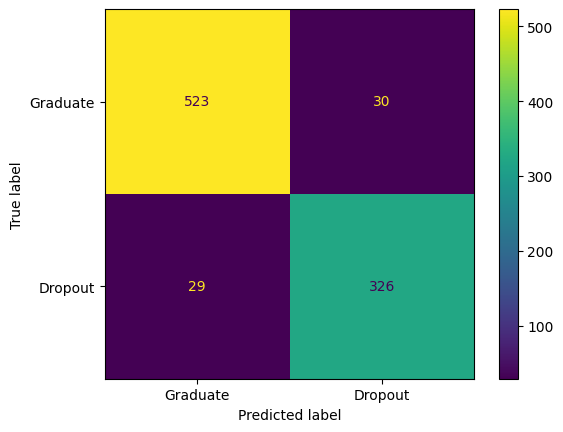

In [45]:
# Matriz de confusión del modelo de Regresión Logística

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=['Graduate', 'Dropout']
)

In [46]:
# Métricas
accuracy_rl = accuracy_score(y_test, y_pred_lr)
precision_rl = precision_score(y_test, y_pred_lr)
recall_rl = recall_score(y_test, y_pred_lr)
f1_rl = f1_score(y_test, y_pred_lr)

print("Accuracy:", accuracy_rl)
print("Precision:", precision_rl)
print("Recall:", recall_rl)
print("F1-score:", f1_rl)

Accuracy: 0.9350220264317181
Precision: 0.9157303370786517
Recall: 0.9183098591549296
F1-score: 0.9170182841068917


### Random Forest

In [47]:
# Entrenar el modelo Random Forest

modelo_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

modelo_rf.fit(X_train, y_train)


y_pred_rf = modelo_rf.predict(X_test)

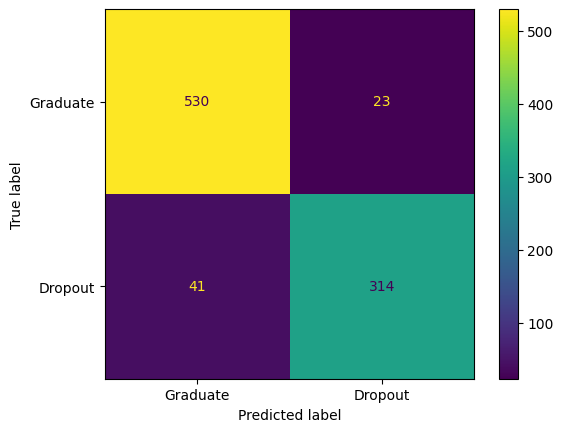

In [48]:
# Matriz de confusión del modelo Random Forest

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=['Graduate', 'Dropout']
)

In [49]:
# Métricas para Random Forest

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-score:", f1_rf)

Accuracy: 0.9295154185022027
Precision: 0.9317507418397626
Recall: 0.8845070422535212
F1-score: 0.9075144508670521


### Support Vector Machine

In [50]:
# Entrenar con el modelo Support Vector Machine

modelo_svm = SVC(
    kernel='rbf',
    random_state=42
)

modelo_svm.fit(X_train_scaled, y_train)

y_pred_svm = modelo_svm.predict(X_test_scaled)

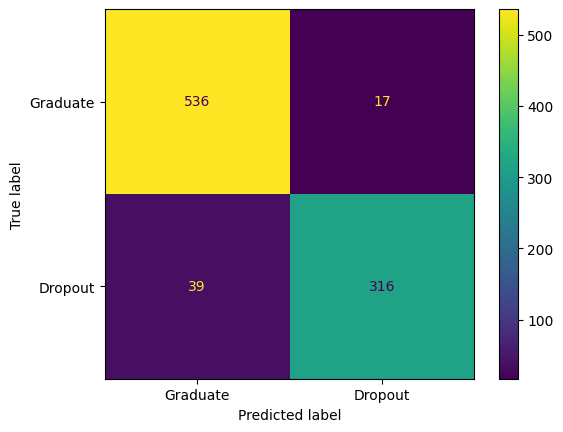

In [51]:
# Matriz de confusión del modelo SVM

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    display_labels=['Graduate', 'Dropout']
)

In [52]:
# Métricas para Support Vector Machine

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1-score:", f1_svm)

Accuracy: 0.9383259911894273
Precision: 0.948948948948949
Recall: 0.8901408450704226
F1-score: 0.9186046511627907


## Evaluación

In [53]:
# Construir una tabla comparativa con las métricas de evaluación de los tres modelos

resultados = pd.DataFrame({
    'Modelo': [
        'Regresión Logística',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_rl,
        accuracy_rf,
        accuracy_svm
    ],
    'Precision': [
        precision_rl,
        precision_rf,
        precision_svm
    ],
    'Recall': [
        recall_rl,
        recall_rf,
        recall_svm
    ],
    'F1-score': [
        f1_rl,
        f1_rf,
        f1_svm
    ]
})
resultados

,Modelo,Accuracy,Precision,Recall,F1-score
0,Regresión Logística,0.935022,0.915730,0.918310,0.917018
1,Random Forest,0.929515,0.931751,0.884507,0.907514
2,SVM,0.938326,0.948949,0.890141,0.918605


In [54]:
# Definir una validación cruzada de 5 folds y verificar la división del conjunto de entrenamiento en cada partición


kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for i, (indices_entrenamiento, indices_validacion) in enumerate(kf.split(X_train)):

    X_entrenamiento_fold = X_train.iloc[indices_entrenamiento]
    X_validacion_fold = X_train.iloc[indices_validacion]

    y_entrenamiento_fold = y_train.iloc[indices_entrenamiento]
    y_validacion_fold = y_train.iloc[indices_validacion]

    print(f"Fold {i+1}")
    print(X_entrenamiento_fold.shape)
    print(X_validacion_fold.shape)

Fold 1
(2177, 69)
(545, 69)
Fold 2
(2177, 69)
(545, 69)
Fold 3
(2178, 69)
(544, 69)
Fold 4
(2178, 69)
(544, 69)
Fold 5
(2178, 69)
(544, 69)


In [55]:
# Validación cruzada Regresión Logística

recalls = []

for i, (indices_entrenamiento, indices_validacion) in enumerate(kf.split(X_train)):

    X_entrenamiento_fold = X_train_scaled.iloc[indices_entrenamiento]
    X_validacion_fold = X_train_scaled.iloc[indices_validacion]

    y_entrenamiento_fold = y_train.iloc[indices_entrenamiento]
    y_validacion_fold = y_train.iloc[indices_validacion]

    modelo_fold = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    modelo_fold.fit(
        X_entrenamiento_fold,
        y_entrenamiento_fold
    )

    y_pred_fold = modelo_fold.predict(X_validacion_fold)

    recall_fold = recall_score(
        y_validacion_fold,
        y_pred_fold
    )

    recalls.append(recall_fold)

    print(f"Fold {i+1}: Recall = {recall_fold:.4f}")


print("Recall promedio:", np.mean(recalls))
print("Desvío estándar:", np.std(recalls))

Fold 1: Recall = 0.8235
Fold 2: Recall = 0.8717
Fold 3: Recall = 0.8084
Fold 4: Recall = 0.8477
Fold 5: Recall = 0.8317
Recall promedio: 0.8366137095837118
Desvío estándar: 0.021649118592082073


In [56]:
# Validación cruzada para Random Forest
recalls_rf = []

for i, (indices_entrenamiento, indices_validacion) in enumerate(kf.split(X_train)):

    X_entrenamiento_fold = X_train.iloc[indices_entrenamiento]
    X_validacion_fold = X_train.iloc[indices_validacion]

    y_entrenamiento_fold = y_train.iloc[indices_entrenamiento]
    y_validacion_fold = y_train.iloc[indices_validacion]

    modelo_rf_fold = RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )

    modelo_rf_fold.fit(
        X_entrenamiento_fold,
        y_entrenamiento_fold
    )

    y_pred_rf_fold = modelo_rf_fold.predict(X_validacion_fold)

    recall_rf_fold = recall_score(
        y_validacion_fold,
        y_pred_rf_fold
    )

    recalls_rf.append(recall_rf_fold)

    print(f"Fold {i+1}: Recall = {recall_rf_fold:.4f}")

print("Recall promedio:", np.mean(recalls_rf))
print("Desvío estándar:", np.std(recalls_rf))

Fold 1: Recall = 0.8009
Fold 2: Recall = 0.8274
Fold 3: Recall = 0.7757
Fold 4: Recall = 0.8173
Fold 5: Recall = 0.8317
Recall promedio: 0.8106058385506179
Desvío estándar: 0.020426253877037743


In [57]:
# Validación cruzada Support Vector Machine
recalls_svm = []

for i, (indices_entrenamiento, indices_validacion) in enumerate(kf.split(X_train_scaled)):

    X_entrenamiento_fold = X_train_scaled.iloc[indices_entrenamiento]
    X_validacion_fold = X_train_scaled.iloc[indices_validacion]

    y_entrenamiento_fold = y_train.iloc[indices_entrenamiento]
    y_validacion_fold = y_train.iloc[indices_validacion]

    modelo_svm_fold = SVC(
        kernel='rbf',
        random_state=42
    )

    modelo_svm_fold.fit(
        X_entrenamiento_fold,
        y_entrenamiento_fold
    )

    y_pred_svm_fold = modelo_svm_fold.predict(X_validacion_fold)

    recall_svm_fold = recall_score(
        y_validacion_fold,
        y_pred_svm_fold
    )

    recalls_svm.append(recall_svm_fold)

    print(f"Fold {i+1}: Recall = {recall_svm_fold:.4f}")

print("Recall promedio:", np.mean(recalls_svm))
print("Desvío estándar:", np.std(recalls_svm))

Fold 1: Recall = 0.8054
Fold 2: Recall = 0.8363
Fold 3: Recall = 0.7477
Fold 4: Recall = 0.7868
Fold 5: Recall = 0.8029
Recall promedio: 0.7958126494674878
Desvío estándar: 0.028913300524135172


In [58]:
resultados_recall = pd.DataFrame({
    'Modelo': [
        'Regresión Logística',
        'Random Forest',
        'SVM'
    ],
    'Recall promedio': [
        np.mean(recalls),
        np.mean(recalls_rf),
        np.mean(recalls_svm)
    ],
    'Desvío estándar': [
        np.std(recalls),
        np.std(recalls_rf),
        np.std(recalls_svm)
    ]
})

display(resultados_recall)

,Modelo,Recall promedio,Desvío estándar
0,Regresión Logística,0.836614,0.021649
1,Random Forest,0.810606,0.020426
2,SVM,0.795813,0.028913


### Análisis de variables relevantes

In [59]:
# Obtener el coeficiente asociado a cada variable predictora en la Regresión Logística
coeficientes = pd.DataFrame({
    'Variable': X_train_scaled.columns,
    'Coeficiente': modelo_lr.coef_[0]
})


coeficientes['Magnitud_abs'] = coeficientes['Coeficiente'].abs()

coeficientes_ordenados = coeficientes.sort_values(
    by='Magnitud_abs',
    ascending=False
)

coeficientes_ordenados.head(15)

,Variable,Coeficiente,Magnitud_abs
21,Curricular units 2nd sem (approved),-2.651030,2.651030
15,Curricular units 1st sem (approved),-2.126813,2.126813
7,Tuition fees up to date,-2.119950,2.119950
19,Curricular units 2nd sem (enrolled),1.617375,1.617375
30,isced_Educación,1.374854,1.374854
34,isced_Tecnologías de la Información y la Comun...,1.317913,1.317913
6,Debtor,1.051785,1.051785
13,Curricular units 1st sem (enrolled),0.816056,0.816056
22,Curricular units 2nd sem (grade),-0.684840,0.684840
68,ocpP_Otra_o_desconocida,0.666190,0.666190


##### En la Regresión Logística, dado que la variable objetivo fue codificada como 0 = Graduate y 1 = Dropout, los coeficientes positivos se asocian con una mayor probabilidad que los estudiantes abandonden mientras que los coeficientes negativos se asocian con una mayor probabilidad de graduación. 
##### Los coeficientes de mayor magnitud se concentran principalmente en variables vinculadas con el desempeño académico y con la situación económico-administrativa del estudiante. La cantidad de unidades curriculares aprobadas en ambos semestres presenta coeficientes negativos de magnitud elevada, al igual que la condición de estar al día con el pago de la matrícula.
##### Por el contrario, la condición de deudor presenta un coeficiente positivo. Estos resultados sugieren que dichas dimensiones presentan una relevancia predictiva destacada en relación con el riesgo de deserción.

In [60]:
# Obtener la importancia de cada variable predictora en el modelo Random Forest

importancias_rf = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': modelo_rf.feature_importances_
})

importancias_rf = importancias_rf.sort_values(
    by='Importancia',
    ascending=False
)

importancias_rf.head(15)

,Variable,Importancia
21,Curricular units 2nd sem (approved),0.197039
15,Curricular units 1st sem (approved),0.127726
22,Curricular units 2nd sem (grade),0.116369
16,Curricular units 1st sem (grade),0.070696
7,Tuition fees up to date,0.047367
20,Curricular units 2nd sem (evaluations),0.033176
10,Age at enrollment,0.031741
14,Curricular units 1st sem (evaluations),0.029130
3,Admission grade,0.028755
2,Previous qualification (grade),0.026346


##### El análisis de importancia de variables del modelo Random Forest muestra un predominio de las características vinculadas con el desempeño académico. 
#####  Las unidades curriculares aprobadas y las calificaciones de ambos semestres presentan las mayores importancias, destacándose especialmente las correspondientes al segundo semestre. Asimismo, aparecen entre las variables destacadas características económico-financieras, como la situación respecto del pago de la matrícula, la condición de becario y la condición de deudor. 
#####  Estos resultados presentan coincidencias con los obtenidos mediante Regresión Logística, particularmente en relación con el peso de las dimensiones académica y económico-financiera.